# Exploratory Data Analysis — Azure VM CPU readings & VM metadata (data-v1)
**Why:** understand what the data represents before forecasting (cadence, quality, churn, distributions, segments, peaks) and why each finding matters operationally.
**How:** Part A = `vm_cpu_readings` · Part B = `vm_metadata` · Part C = both joined on `vm_id` · Part D = key findings.
All CPU values are **percent (0–100)**, so `aggregate_cpu_utilization` is already a percentage (no rescaling).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
DATA = "../challenge_data"
cpu  = pd.read_csv(f"{DATA}/vm_cpu_readings.csv.gz")
meta = pd.read_csv(f"{DATA}/vm_metadata.csv.gz")
print(cpu.shape, meta.shape)

(1340000, 5) (10000, 11)


# Part A — CPU readings

## A1. Structure and quality

In [2]:
display(cpu.head()); display(cpu.dtypes.to_frame("dtype"))
q = {
 "rows": len(cpu), "VMs": cpu.vm_id.nunique(), "timestamps": cpu.timestamp.nunique(),
 "nulls": int(cpu.isna().sum().sum()), "duplicate rows": int(cpu.duplicated().sum()),
 "duplicate (vm_id, timestamp)": int(cpu.duplicated(["vm_id","timestamp"]).sum()),
 "avg_cpu outside [0,100]": int((~cpu.avg_cpu.between(0,100)).sum()),
 "min>avg or avg>max violations": int(((cpu.min_cpu>cpu.avg_cpu+1e-9)|(cpu.avg_cpu>cpu.max_cpu+1e-9)).sum()),
 "timestamp spacing (s)": np.unique(np.diff(np.sort(cpu.timestamp.unique()))).tolist(),
 "span (hours)": round((cpu.timestamp.max()-cpu.timestamp.min())/3600 + 5/60, 2),
}
display(pd.Series(q, name="value").to_frame())
per_vm = cpu.groupby("vm_id").size(); per_ts = cpu.groupby("timestamp").vm_id.nunique()
print("obs per VM:", per_vm.min(), "-", per_vm.max(), "| VMs per timestamp:", per_ts.min(), "-", per_ts.max())

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


,dtype
timestamp,int64
vm_id,str
min_cpu,float64
max_cpu,float64
avg_cpu,float64


,value
rows,1340000
VMs,10000
timestamps,134
nulls,0
duplicate rows,0
"duplicate (vm_id, timestamp)",0
"avg_cpu outside [0,100]",0
min>avg or avg>max violations,0
timestamp spacing (s),[300]
span (hours),11.17


obs per VM: 134 - 134 | VMs per timestamp: 10000 - 10000


**Why it matters:** a perfectly regular, complete panel means no imputation is needed and every timestamp represents the same 10,000-VM population — so `active_vm_count` carries no information (constant) and all forecasting signal sits in CPU levels.

## A2. Distribution of CPU readings

,min_cpu,avg_cpu,max_cpu
count,1340000.00,1340000.00,1340000.00
mean,6.16,9.39,18.35
std,11.76,14.27,21.62
min,0.00,0.01,0.02
50%,3.23,5.11,9.12
75%,5.33,9.62,23.62
90%,11.23,19.60,51.93
95%,22.83,37.13,65.64
99%,78.20,87.35,97.54
max,99.28,99.49,99.70


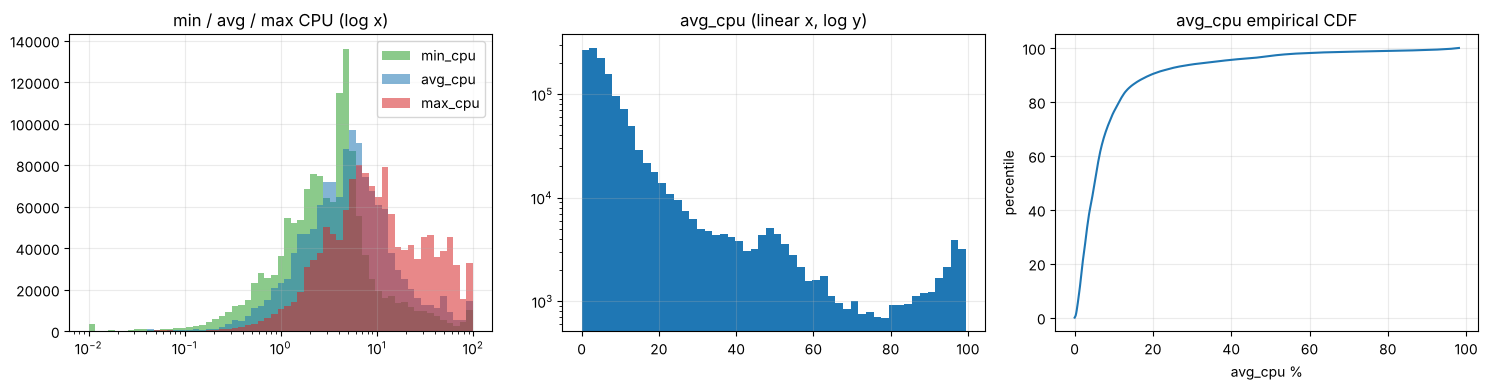

,% of VM-readings
avg_cpu,
"(-0.001, 1.0]",7.59
"(1.0, 5.0]",41.46
"(5.0, 10.0]",27.13
"(10.0, 25.0]",16.25
"(25.0, 50.0]",4.50
"(50.0, 75.0]",1.68
"(75.0, 100.0]",1.40


In [3]:
display(cpu[["min_cpu","avg_cpu","max_cpu"]].describe(percentiles=[.5,.75,.9,.95,.99]).round(2))
fig, ax = plt.subplots(1,3, figsize=(15,4))
bins = np.logspace(-2, 2, 60)
for c, col in zip(["min_cpu","avg_cpu","max_cpu"], ["#2ca02c","#1f77b4","#d62728"]):
    ax[0].hist(cpu[c].clip(lower=1e-2), bins=bins, alpha=.55, label=c, color=col)
ax[0].set_xscale("log"); ax[0].set_title("min / avg / max CPU (log x)"); ax[0].legend()
ax[1].hist(cpu.avg_cpu, bins=50, color="#1f77b4"); ax[1].set_yscale("log"); ax[1].set_title("avg_cpu (linear x, log y)")
s = np.sort(cpu.avg_cpu.to_numpy()); ax[2].plot(s[::2000], np.linspace(0,100,len(s[::2000]))); ax[2].set_title("avg_cpu empirical CDF"); ax[2].set_xlabel("avg_cpu %"); ax[2].set_ylabel("percentile")
plt.tight_layout(); plt.show()
bands = pd.cut(cpu.avg_cpu, [0,1,5,10,25,50,75,100], include_lowest=True).value_counts(normalize=True).sort_index().mul(100).round(2)
display(bands.to_frame("% of VM-readings"))

**Why it matters:** the distribution is strongly right-skewed — most VM-readings are nearly idle while a thin tail runs hot. The mean (≈ 9 %) is therefore dominated by the tail and is not what a typical VM experiences.

## A3. Burstiness: how far above average do VMs spike?

In [4]:
cpu["spike"] = cpu.max_cpu - cpu.avg_cpu
display(cpu.spike.describe(percentiles=[.5,.9,.99]).round(2).to_frame("max_cpu - avg_cpu (pp)").T)
print("readings where max_cpu >= 90%:", (cpu.max_cpu>=90).mean().round(4)*100, "%  | avg_cpu >= 90%:", (cpu.avg_cpu>=90).mean().round(5)*100, "%")
print(cpu[["min_cpu","avg_cpu","max_cpu"]].corr().round(3))

,count,mean,std,min,50%,90%,99%,max
max_cpu - avg_cpu (pp),1340000.0,8.96,12.79,0.0,3.28,26.33,54.76,95.52


readings where max_cpu >= 90%: 2.11 %  | avg_cpu >= 90%: 0.88 %
         min_cpu  avg_cpu  max_cpu
min_cpu    1.000    0.931    0.645
avg_cpu    0.931    1.000    0.822
max_cpu    0.645    0.822    1.000


**Why it matters:** `max_cpu` is far above `avg_cpu` in the 5-minute window, so averages hide short bursts; headroom sized on mean CPU alone under-protects bursty VMs.

## A4. Time structure of the fleet

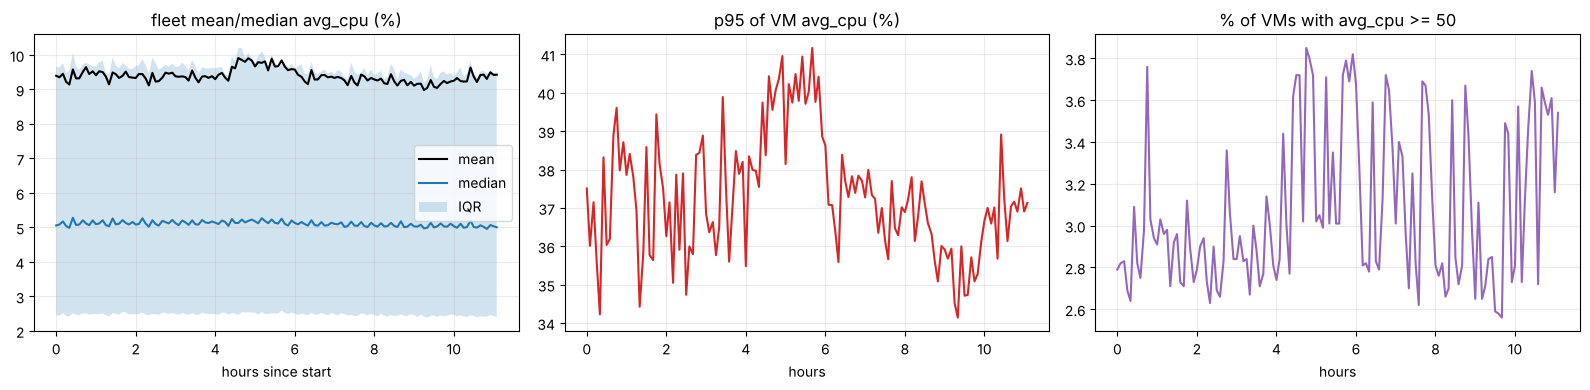

mean: 9.388 | std: 0.195 | min/max: 8.984 9.912 | range as % of mean: 9.9
autocorrelation: {1: np.float64(0.68), 2: np.float64(0.62), 6: np.float64(0.53), 12: np.float64(0.44), 24: np.float64(0.13), 48: np.float64(-0.17)}
peak slots (step): {55: 9.912, 58: 9.906, 65: 9.892, 56: 9.854, 68: 9.842}
low slots (step): {111: 8.984, 112: 9.043, 115: 9.046, 114: 9.078, 108: 9.112}


In [5]:
g = cpu.groupby("timestamp").avg_cpu
agg = pd.DataFrame({"mean": g.mean(), "median": g.median(), "p25": g.quantile(.25), "p75": g.quantile(.75), "p95": g.quantile(.95), "share_ge50%": g.apply(lambda s:(s>=50).mean()*100)}).reset_index(drop=True)
agg["hour"] = (np.arange(len(agg))*5/60).round(2)
fig, ax = plt.subplots(1,3, figsize=(16,4))
ax[0].plot(agg.hour, agg["mean"], c="k", label="mean"); ax[0].plot(agg.hour, agg["median"], label="median"); ax[0].fill_between(agg.hour, agg.p25, agg.p75, alpha=.2, label="IQR"); ax[0].set_title("fleet mean/median avg_cpu (%)"); ax[0].set_xlabel("hours since start"); ax[0].legend()
ax[1].plot(agg.hour, agg.p95, c="#d62728"); ax[1].set_title("p95 of VM avg_cpu (%)"); ax[1].set_xlabel("hours")
ax[2].plot(agg.hour, agg["share_ge50%"], c="#9467bd"); ax[2].set_title("% of VMs with avg_cpu >= 50"); ax[2].set_xlabel("hours")
plt.tight_layout(); plt.show()
y = agg["mean"]
print("mean:", y.mean().round(3), "| std:", y.std().round(3), "| min/max:", y.min().round(3), y.max().round(3), "| range as % of mean:", ((y.max()-y.min())/y.mean()*100).round(1))
print("autocorrelation:", {l: round(y.autocorr(l),2) for l in (1,2,6,12,24,48)})
print("peak slots (step):", y.nlargest(5).round(3).to_dict()); print("low slots (step):", y.nsmallest(5).round(3).to_dict())

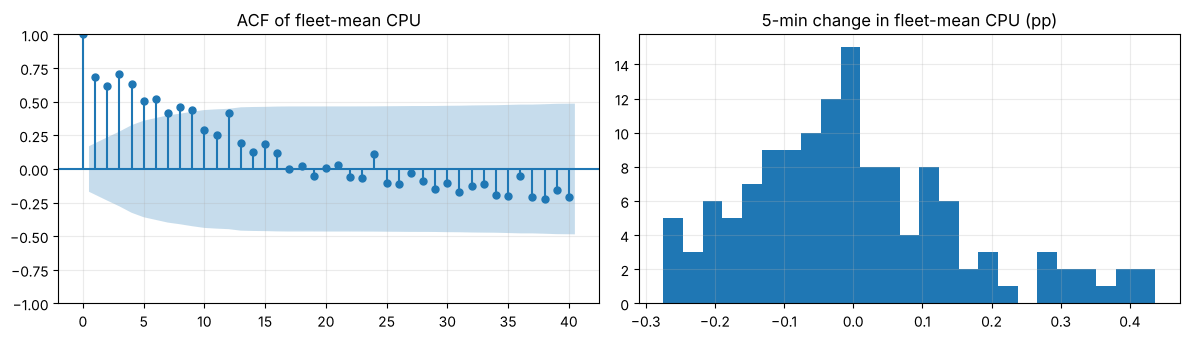

step-to-step SD (pp): 0.156


In [6]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(1,2, figsize=(12,3.5)); plot_acf(y, lags=40, ax=ax[0]); ax[0].set_title("ACF of fleet-mean CPU")
ax[1].hist(y.diff().dropna(), bins=25); ax[1].set_title("5-min change in fleet-mean CPU (pp)"); plt.tight_layout(); plt.show()
print("step-to-step SD (pp):", y.diff().std().round(3))

**Why it matters:** the fleet mean moves by less than 1 pp in total, with a noisy ±0.16 pp step-to-step wobble and one slower level shift. That sets the *noise floor* for any forecast: models can only be judged on differences of a few hundredths of a percentage point. With only 11 h of data, daily or weekly seasonality cannot be observed.

## A5. VM-level behaviour (persistence, volatility, churn of ranks)

,mean,std,max,min,cv
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,9.39,3.01,21.08,5.96,0.37
std,13.02,5.03,21.93,9.31,0.40
min,0.01,0.00,0.01,0.01,0.00
50%,5.48,1.35,13.08,3.60,0.29
90%,19.52,6.46,50.85,10.92,0.66
99%,78.37,28.58,98.13,49.12,2.07
max,99.27,46.52,99.49,99.16,6.00


rank correlation of VM mean CPU, first half vs second half: 0.964


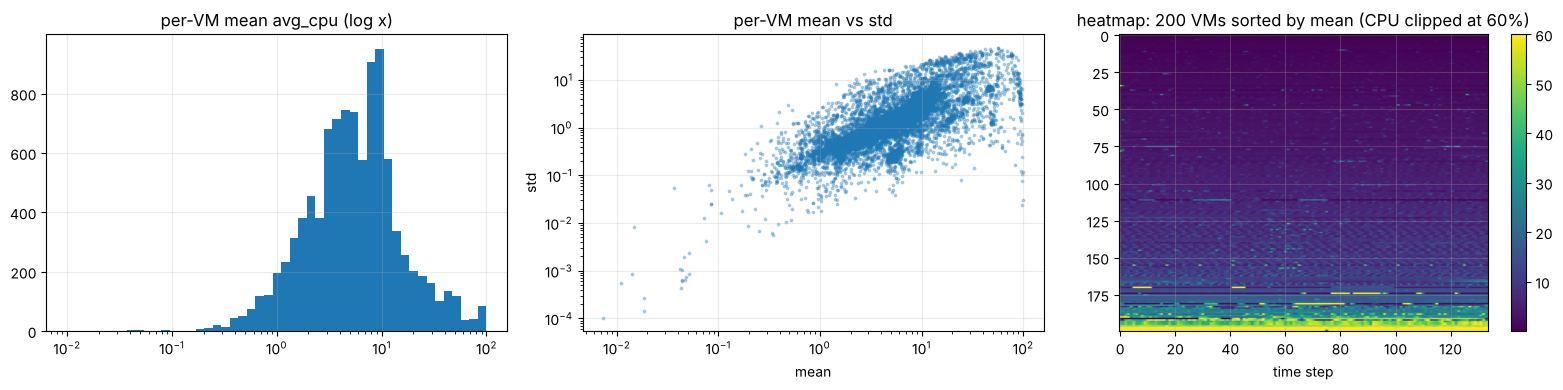

VMs with mean avg_cpu < 5%: 0.464 | > 50%: 0.0221


In [7]:
vm = cpu.groupby("vm_id").avg_cpu.agg(mean="mean", std="std", max="max", min="min")
vm["cv"] = vm["std"]/vm["mean"].clip(lower=1e-3)
display(vm.describe(percentiles=[.5,.9,.99]).round(2))
wide = cpu.pivot(index="vm_id", columns="timestamp", values="avg_cpu")
first, last = wide.iloc[:, :67].mean(axis=1), wide.iloc[:, 67:].mean(axis=1)
print("rank correlation of VM mean CPU, first half vs second half:", first.corr(last, method="spearman").round(3))
fig, ax = plt.subplots(1,3, figsize=(16,4))
ax[0].hist(vm["mean"], bins=np.logspace(-2,2,50)); ax[0].set_xscale("log"); ax[0].set_title("per-VM mean avg_cpu (log x)")
ax[1].scatter(vm["mean"], vm["std"], s=3, alpha=.3); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_title("per-VM mean vs std"); ax[1].set_xlabel("mean"); ax[1].set_ylabel("std")
samp = wide.loc[vm["mean"].sort_values().index[::50]]; im = ax[2].imshow(samp.clip(upper=60).to_numpy(), aspect="auto", cmap="viridis"); ax[2].set_title("heatmap: 200 VMs sorted by mean (CPU clipped at 60%)"); ax[2].set_xlabel("time step"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()
print("VMs with mean avg_cpu < 5%:", (vm['mean']<5).mean().round(3), "| > 50%:", (vm['mean']>50).mean().round(4))

**Why it matters:** VM identity explains most of the variance (rank correlation between halves is high) — a VM that is busy now will be busy in two hours. Aggregate CPU is therefore stable because the *composition* is stable.

# Part B — VM metadata

## B1. Structure and quality

In [8]:
display(meta.head(3).assign(vm_id=lambda d:d.vm_id.str[:8], subscription_id=lambda d:d.subscription_id.str[:8], deployment_id=lambda d:d.deployment_id.str[:8]))
display(pd.DataFrame({"dtype": meta.dtypes.astype(str), "nulls": meta.isna().sum(), "unique": meta.nunique()}))
print("duplicate rows:", meta.duplicated().sum(), "| vm_id unique:", meta.vm_id.is_unique, "| match with readings:", set(meta.vm_id)==set(cpu.vm_id))

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf,zidmVREt,gFCpVCrX,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WP,JOJ5q+T2,+qsl6upF,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1L,0kctkGk3,TJuS+gMf,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4


,dtype,nulls,unique
vm_id,str,0,10000
subscription_id,str,0,2324
deployment_id,str,0,2359
timestamp_vm_created,int64,0,1
timestamp_vm_deleted,int64,0,1071
max_cpu,float64,0,9997
avg_cpu,float64,0,10000
p95_max_cpu,float64,0,10000
vm_category,str,0,3
virtual_core_bucket,str,0,5


duplicate rows: 0 | vm_id unique: True | match with readings: True


In [9]:
display(meta[["timestamp_vm_created","timestamp_vm_deleted","max_cpu","avg_cpu","p95_max_cpu"]].describe().round(2))
for c in ["vm_category","virtual_core_bucket","memory_gb_bucket"]:
    print(f"\n{c}"); print(meta[c].value_counts().to_frame("VMs").assign(share_pct=lambda d:(d.VMs/len(meta)*100).round(1)).to_string())

,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,0.0,2289625.62,86.49,9.34,36.37
std,0.0,708100.83,18.76,11.25,29.44
min,0.0,40500.00,0.03,0.01,0.03
25%,0.0,2591400.00,82.30,3.05,10.59
50%,0.0,2591400.00,95.42,5.86,23.98
75%,0.0,2591400.00,98.38,10.53,62.03
max,0.0,2591400.00,100.00,99.20,99.52



vm_category
                    VMs  share_pct
vm_category                       
Delay-insensitive  6180       61.8
Interactive        3091       30.9
Unknown             729        7.3

virtual_core_bucket
                      VMs  share_pct
virtual_core_bucket                 
2                    7534       75.3
4                    1908       19.1
8                     486        4.9
24                     62        0.6
>24                    10        0.1

memory_gb_bucket
                   VMs  share_pct
memory_gb_bucket                 
2                 3904       39.0
4                 2475       24.8
8                 2146       21.5
32                1383       13.8
64                  82        0.8
>64                 10        0.1


## B2. Lifetimes and churn

created at t=0: 1.0 | deleted inside trace window: 0 | earliest deletion: 40500 s vs trace end 39900 s
lifetime (days):
count    10000.00
mean        26.50
std          8.20
min          0.47
10%          8.75
25%         29.99
50%         29.99
max         29.99
share living the whole 30-day source trace (>= 29.99 d): 0.821


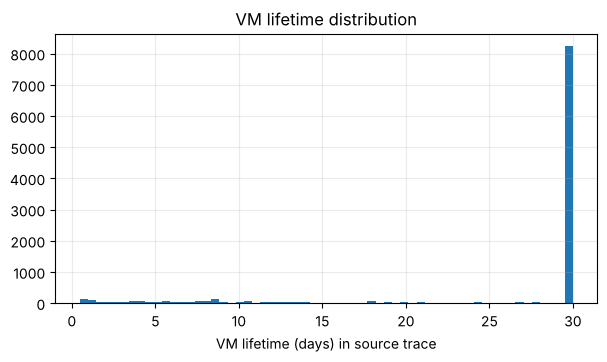

In [10]:
end = cpu.timestamp.max()
meta["lifetime_days"] = (meta.timestamp_vm_deleted - meta.timestamp_vm_created)/86400
print("created at t=0:", (meta.timestamp_vm_created==0).mean(), "| deleted inside trace window:", (meta.timestamp_vm_deleted<=end).sum(), "| earliest deletion:", meta.timestamp_vm_deleted.min(), "s vs trace end", end, "s")
print("lifetime (days):"); print(meta.lifetime_days.describe(percentiles=[.1,.25,.5]).round(2).to_string())
print("share living the whole 30-day source trace (>= 29.99 d):", (meta.lifetime_days>=29.99).mean().round(3))
fig, ax = plt.subplots(figsize=(7,3.5)); ax.hist(meta.lifetime_days, bins=60); ax.set_xlabel("VM lifetime (days) in source trace"); ax.set_title("VM lifetime distribution"); plt.show()

**Why it matters:** every VM is alive for the whole observation window, so there is **zero churn** and `active_vm_count` is constant. The sample was built from VMs with complete traces — a survivorship filter — so it cannot show fleet growth/shrinkage. Note that 17.9 % of VMs are deleted *after* the window (lifetimes of 0.5–29 days in the 30-day source trace), so churn exists in the source data but is invisible here.

## B3. Subscriptions and deployments (who owns the VMs?)

subscriptions: 2324 | deployments: 2359
VMs per subscription  - median: 1.0 | p90: 8.0 | max: 96
VMs per deployment    - median: 1.0 | p90: 8.0 | max: 96
top-10 subscriptions hold 8.8 % of VMs | top-10 deployments: 8.8 %


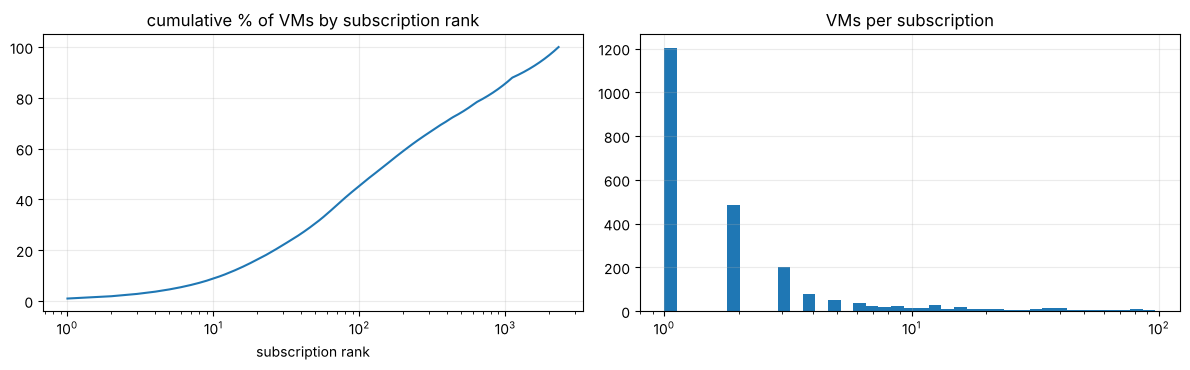

In [11]:
sub = meta.groupby("subscription_id").size().sort_values(ascending=False); dep = meta.groupby("deployment_id").size().sort_values(ascending=False)
print("subscriptions:", len(sub), "| deployments:", len(dep))
print("VMs per subscription  - median:", sub.median(), "| p90:", sub.quantile(.9), "| max:", sub.max())
print("VMs per deployment    - median:", dep.median(), "| p90:", dep.quantile(.9), "| max:", dep.max())
print("top-10 subscriptions hold", (sub.head(10).sum()/len(meta)*100).round(1), "% of VMs | top-10 deployments:", (dep.head(10).sum()/len(meta)*100).round(1), "%")
fig, ax = plt.subplots(1,2, figsize=(12,3.8))
ax[0].plot(np.arange(1,len(sub)+1), sub.cumsum()/len(meta)*100); ax[0].set_xscale("log"); ax[0].set_title("cumulative % of VMs by subscription rank"); ax[0].set_xlabel("subscription rank")
ax[1].hist(sub, bins=np.logspace(0, np.log10(sub.max()+1), 40)); ax[1].set_xscale("log"); ax[1].set_title("VMs per subscription"); plt.tight_layout(); plt.show()

**Why it matters:** ownership is highly fragmented (2,324 subscriptions; median 1 VM, max 96; the top 10 hold only 8.8 % of VMs). No single tenant can move the fleet aggregate on its own, which is one reason the aggregate is so stable.

## B4. Metadata CPU statistics vs. what we observe

corr(metadata avg_cpu [30-day], observed mean in 11h window): 0.871 | Spearman: 0.934
mean metadata avg_cpu: 9.34 | mean observed avg_cpu: 9.39


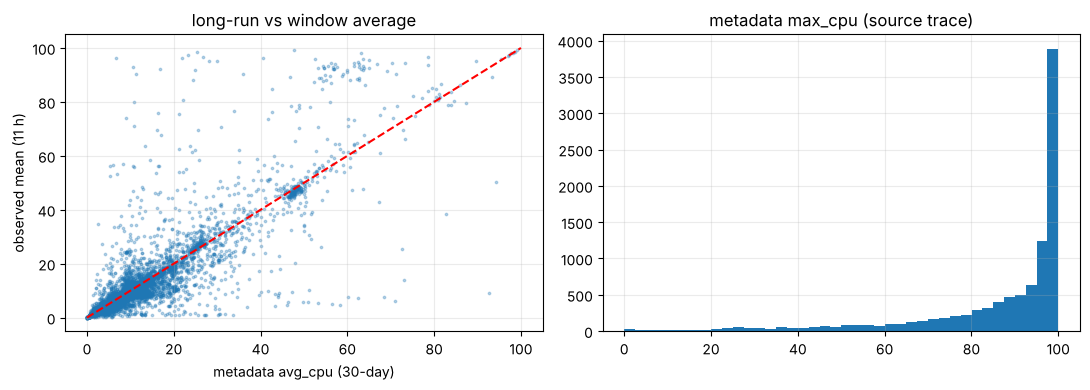

In [12]:
m = meta[["vm_id","avg_cpu","max_cpu","p95_max_cpu"]].merge(vm.reset_index()[["vm_id","mean","max"]], on="vm_id", suffixes=("_meta","_obs"))
print("corr(metadata avg_cpu [30-day], observed mean in 11h window):", m.avg_cpu.corr(m["mean"]).round(3), "| Spearman:", m.avg_cpu.corr(m["mean"], method="spearman").round(3))
print("mean metadata avg_cpu:", meta.avg_cpu.mean().round(2), "| mean observed avg_cpu:", cpu.avg_cpu.mean().round(2))
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].scatter(m.avg_cpu, m["mean"], s=3, alpha=.3); ax[0].plot([0,100],[0,100],"r--"); ax[0].set_xlabel("metadata avg_cpu (30-day)"); ax[0].set_ylabel("observed mean (11 h)"); ax[0].set_title("long-run vs window average")
ax[1].hist(meta.max_cpu, bins=40); ax[1].set_title("metadata max_cpu (source trace)"); plt.tight_layout(); plt.show()

**Why it matters:** metadata statistics cover the long source trace while readings cover 11 h. A strong agreement means metadata (e.g. its average) is a legitimate *static* VM-level covariate, valid at the forecast origin; it is not used as a target.

# Part C — Joined analysis (segments)

In [13]:
d = cpu.merge(meta[["vm_id","vm_category","virtual_core_bucket","memory_gb_bucket","subscription_id","deployment_id"]], on="vm_id")
order_core = ["2","4","8","24",">24"]; d["virtual_core_bucket"] = d.virtual_core_bucket.astype(str)
print(pd.crosstab(meta.vm_category, meta.virtual_core_bucket.astype(str)).reindex(columns=order_core))
for c in ["vm_category","virtual_core_bucket","memory_gb_bucket"]:
    print(f"\n{c}"); print(d.groupby(c).avg_cpu.agg(VMs=lambda s: s.size//134, mean="mean", median="median", p95=lambda s:s.quantile(.95), share_ge50=lambda s:(s>=50).mean()*100).round(2).to_string())

virtual_core_bucket     2     4    8  24  >24
vm_category                                  
Delay-insensitive    4892  1044  206  34    4
Interactive          2212   653  199  21    6
Unknown               430   211   81   7    0

vm_category
                    VMs   mean  median    p95  share_ge50
vm_category                                              
Delay-insensitive  6180   8.24    5.15  25.91        1.91
Interactive        3091  11.49    5.28  49.41        4.81
Unknown             729  10.23    3.38  52.23        5.61

virtual_core_bucket


                      VMs   mean  median    p95  share_ge50
virtual_core_bucket                                        
2                    7534   9.72    5.51  38.99        3.39
24                     62  11.40    6.78  52.45        6.08
4                    1908   7.93    2.90  32.06        2.15
8                     486   9.70    4.28  38.40        1.50
>24                    10   6.62    2.64  23.28        0.15

memory_gb_bucket


                   VMs   mean  median    p95  share_ge50
memory_gb_bucket                                        
2                 3904   8.78    6.68  18.13        1.11
32                1383   7.84    2.67  29.71        1.21
4                 2475  11.34    4.39  58.14        6.31
64                  82  11.27    4.37  50.70        5.31
8                 2146   9.18    2.85  47.68        4.07
>64                 10   6.62    2.64  23.28        0.15


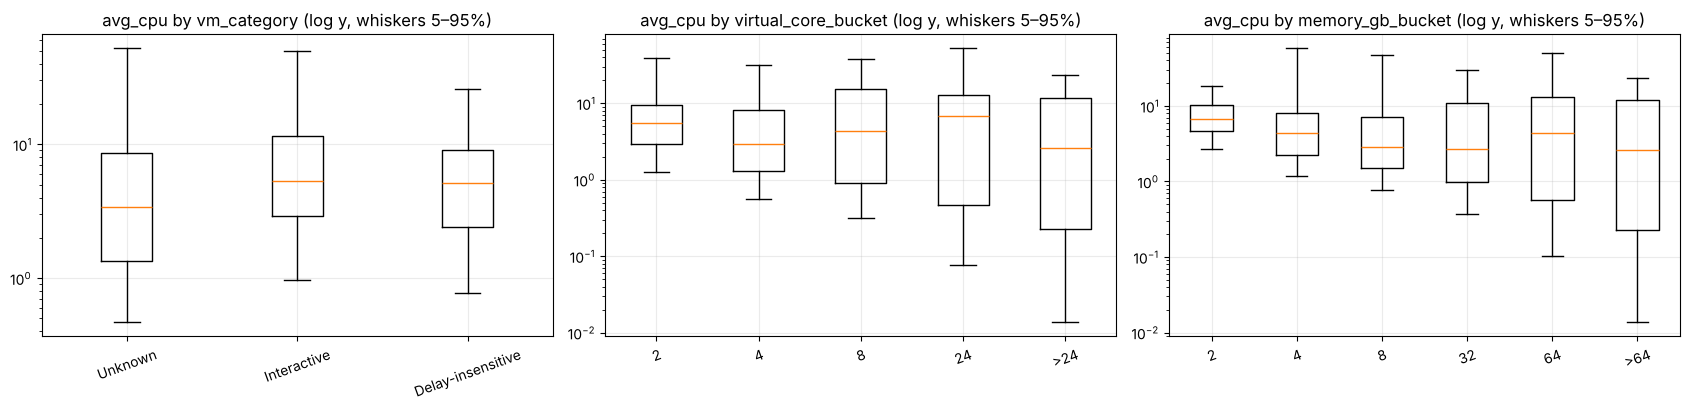

In [14]:
fig, ax = plt.subplots(1,3, figsize=(17,4.2))
for a_, c in zip(ax, ["vm_category","virtual_core_bucket","memory_gb_bucket"]):
    keys = sorted(d[c].unique(), key=lambda v: (len(str(v)), str(v)))
    a_.boxplot([d.loc[d[c]==k,"avg_cpu"].clip(lower=1e-2) for k in keys], showfliers=False, whis=(5,95)); a_.set_xticks(range(1,len(keys)+1)); a_.set_xticklabels([str(k) for k in keys]); a_.set_yscale("log"); a_.set_title(f"avg_cpu by {c} (log y, whiskers 5–95%)"); a_.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

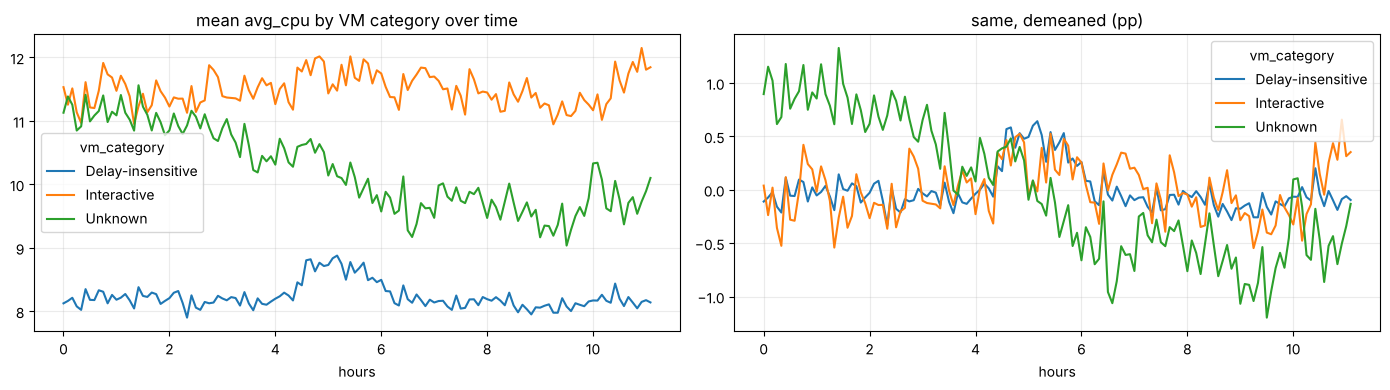

step-to-step SD of segment mean (pp):
vm_category
Delay-insensitive    0.134
Interactive          0.257
Unknown              0.266

by cores:
virtual_core_bucket
2      0.174
24     0.292
4      0.153
8      0.294
>24    2.640


In [15]:
seg = d.groupby(["timestamp","vm_category"]).avg_cpu.mean().unstack(); seg.index = np.arange(len(seg))*5/60
fig, ax = plt.subplots(1,2, figsize=(14,4))
seg.plot(ax=ax[0]); ax[0].set_title("mean avg_cpu by VM category over time"); ax[0].set_xlabel("hours")
(seg - seg.mean()).plot(ax=ax[1]); ax[1].set_title("same, demeaned (pp)"); ax[1].set_xlabel("hours"); plt.tight_layout(); plt.show()
print("step-to-step SD of segment mean (pp):"); print(seg.diff().std().round(3).to_string())
sc = d.groupby(["timestamp","virtual_core_bucket"]).avg_cpu.mean().unstack(); print("\nby cores:"); print(sc.diff().std().round(3).to_string())

**Why it matters:** Interactive and Unknown VMs have higher means, much fatter tails and ≈ 2× the step-to-step volatility of Delay-insensitive VMs — a segment-specific headroom rule is justified.

## C2. What drives the fleet aggregate?

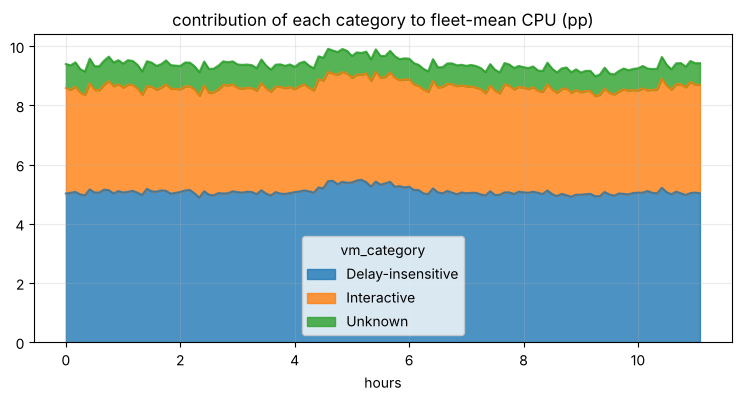

share of variance of the fleet mean explained by each category (covariance share):
vm_category
Delay-insensitive    0.59
Interactive          0.32
Unknown              0.09


In [16]:
# contribution of each category to the fleet mean at each timestamp (weights = VM share)
w = meta.vm_category.value_counts(normalize=True)
contrib = seg.mul(w, axis=1)
fig, ax = plt.subplots(figsize=(9,4)); contrib.plot.area(ax=ax, alpha=.8); ax.set_title("contribution of each category to fleet-mean CPU (pp)"); ax.set_xlabel("hours"); plt.show()
dev = (seg - seg.mean()).mul(w, axis=1)
print("share of variance of the fleet mean explained by each category (covariance share):")
tot = dev.sum(axis=1); print((dev.apply(lambda s: np.cov(s, tot)[0,1])/tot.var()).round(2).to_string())

# Part D — Key findings (numbers produced by the cells above)
| # | Finding | Why it matters |
|---|---|---|
| 1 | Clean, regular panel: 10,000 VMs × 134 slots, 300 s spacing, no nulls/duplicates/out-of-range values, metadata matches 1:1. | No imputation; all modelling effort goes into the signal. |
| 2 | **Zero churn**: every VM is created at t = 0 and none is deleted before 40,500 s (> trace end 39,900 s). `active_vm_count` = 10,000 at every slot. | The count target is constant; the sample is survivorship-filtered and says nothing about fleet growth. |
| 3 | CPU is in **percent (0–100)**; mean 9.39 %, median 5.11 %, p95 37.1 %, p99 87.4 %. 76 % of readings < 10 %; 3.1 % ≥ 50 %. | Aggregate CPU is already a percentage (≈ 9.4 %). The mean is driven by a small hot tail. |
| 4 | Bursty: median `max_cpu − avg_cpu` = 3.3 pp but p99 = 54.8 pp; 2.1 % of readings have `max_cpu ≥ 90 %`. | Mean-based headroom under-protects individual VMs. |
| 5 | Fleet-mean CPU range is 8.98–9.91 % (9.9 % of the mean); step-to-step SD 0.156 pp; lag-1 ACF 0.68, lag-12 0.44, lag-24 0.13. Highest slots at steps 55–68, lowest at steps 108–115. | A very low noise floor: forecast differences are in hundredths of a percentage point; 11 h cannot reveal daily seasonality. |
| 6 | VM identity dominates: Spearman rank correlation of per-VM mean CPU between the first and second half = 0.96; 46 % of VMs average < 5 %, 2.2 % average > 50 %. | Stable composition explains the stable aggregate; VM-level history is a strong predictor. |
| 7 | Metadata `avg_cpu` (30-day) correlates 0.87 (Spearman 0.93) with the observed 11 h mean. | Metadata statistics are valid static covariates (available at the forecast origin). |
| 8 | Segments: Delay-insensitive 61.8 % of VMs (mean 8.2 %, p95 26 %); Interactive 30.9 % (11.5 %, p95 49 %); Unknown 7.3 % (10.2 %, p95 52 %). 75 % of VMs have 2 cores. Interactive/Unknown segment means are ≈ 2× as volatile (0.26 vs 0.13 pp). | Segment-specific headroom is justified. (`>24` cores has only 10 VMs, so its 2.6 pp volatility is noise.) |
| 9 | Ownership is fragmented: 2,324 subscriptions/2,359 deployments, top-10 subscriptions hold 8.8 % of VMs. Delay-insensitive VMs account for ≈ 59 % of the variance of the fleet mean, Interactive 32 %, Unknown 9 %. | No tenant concentration risk; fleet-level movements mostly follow the largest segment. |
| 10 | `timestamp_vm_created` has a single value (0), so it carries no information; 82 % of VMs live the whole 30-day source trace, 18 % end later. | Drop it as a feature; lifetime beyond the window cannot be used at the forecast origin without caution. |